# ModernBERT Baseline on PROMISE Expanded

This notebook follows the same overall experiment style as `Bert_origin.ipynb`, using the PROMISE expanded dataset from GitHub raw URL.

Two runs are provided:

1. ModernBERT without augmentation on raw `RequirementText`
2. ModernBERT with training-only augmentation on raw `RequirementText`

Both runs train for exactly 30 epochs and do not use early stopping.

In [1]:
# --- Colab Setup ---
# ModernBERT support requires transformers >= 4.48.0.
!pip -q install -U "transformers>=4.48.0" accelerate nltk
!pip install transformers pandas torch scikit-learn
!pip install nltk spacy word2number
!python -m spacy download en_core_web_sm
!pip install -U transformers

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.5/11.5 MB 63.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 33.9 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for word2number: filename=word2number-1.1-py3-none-any.whl size=5568 sha256=a983c71c745678d95b03c04a2af587811a26cfc7b956c94f8f24aa830bef068f
  Stored in directory: /root/.cache/pip/wheels/5b/79/fb/d25928e599c7e11fe4e00d32048cd74933f34a74c633d2aea6
Successfully built word2number
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 117.0 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [2]:
# --- Imports ---
import os
import random
import re

import nltk
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import seaborn as sns

from nltk.corpus import stopwords, wordnet
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    precision_recall_fscore_support,
)
from torch.utils.data import Dataset
from transformers import (
    AutoModelForSequenceClassification,
    AutoTokenizer,
    Trainer,
    TrainingArguments,
    TrainerCallback,
    set_seed,
)

from sklearn.utils.class_weight import compute_class_weight

# --- Setup ---
os.environ["WANDB_DISABLED"] = "true"
RANDOM_STATE = 42
MODEL_NAME = "answerdotai/ModernBERT-base"
DATA_URL = "https://raw.githubusercontent.com/egbertbritannia-cpu/rbl-requirements-classification/main/data/exp/promise_exp.csv"
MAX_LENGTH = 128
NUM_EPOCHS = 30
LEARNING_RATE = 2e-5
WEIGHT_DECAY = 0.01
WARMUP_RATIO = 0.1

random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(RANDOM_STATE)
set_seed(RANDOM_STATE)

nltk.download("stopwords")
nltk.download("wordnet")
nltk.download("omw-1.4")
KEEP_WORDS = {'not', 'no', 'shall', 'must', 'should', 'will', 'cannot', 'never', 'only'}
stop_words = set(stopwords.words("english")) - KEEP_WORDS


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...


In [3]:
# --- Text Augmentation Helpers ---
def get_synonyms(word):
    clean_word = re.sub(r"[^a-zA-Z]", "", str(word).lower())
    if not clean_word:
        return []
    synonyms = set()
    for syn in wordnet.synsets(clean_word):
        for lemma in syn.lemmas():
            synonym = lemma.name().replace("_", " ").lower()
            if synonym != clean_word:
                synonyms.add(synonym)
    return list(synonyms)

def synonym_replacement(text, n=1):
    words = str(text).split()
    new_words = words.copy()
    random_word_list = list(set([
        word for word in words
        if re.sub(r"[^a-zA-Z]", "", word).lower() not in stop_words and len(word) > 3
    ]))
    random.shuffle(random_word_list)
    num_replaced = 0
    for random_word in random_word_list:
        synonyms = get_synonyms(random_word)
        if len(synonyms) >= 1:
            synonym = random.choice(synonyms)
            new_words = [synonym if word == random_word else word for word in new_words]
            num_replaced += 1
        if num_replaced >= n:
            break
    return " ".join(new_words)

def phrase_insertion(text, n=1):
    phrases = ["the system shall", "must be able to", "should ensure that"]
    words = str(text).split()
    if len(words) == 0:
        return str(text)
    for _ in range(n):
        add_phrase = random.choice(phrases)
        random_idx = random.randint(0, len(words) - 1)
        words.insert(random_idx, add_phrase)
    return " ".join(words)

def random_deletion(text, p=0.1):
    words = str(text).split()
    if len(words) <= 1:
        return str(text)
    remaining = [word for word in words if random.random() > p]
    return " ".join(remaining) if remaining else random.choice(words)

def random_swap(text, n=1):
    words = str(text).split()
    if len(words) < 2:
        return str(text)
    for _ in range(n):
        idx1, idx2 = random.sample(range(len(words)), 2)
        words[idx1], words[idx2] = words[idx2], words[idx1]
    return " ".join(words)

def augment_text(text):
    aug_text = synonym_replacement(text, 1)
    aug_text = phrase_insertion(aug_text, 1)
    aug_text = random_swap(aug_text, 1)
    aug_text = random_deletion(aug_text, p=0.1)
    return aug_text


In [4]:
# --- Data Loading ---
data_path = DATA_URL
df = pd.read_csv(data_path)
print(f"Loaded PROMISE expanded dataset from: {data_path}")
print("Original shape:", df.shape)
print("Original distribution:", dict(df["class"].value_counts()))

df = df[["RequirementText", "class"]].dropna().reset_index(drop=True)
df["model_text"] = df["RequirementText"].astype(str)
df = df[df["class"].map(df["class"].value_counts()) > 1].reset_index(drop=True)

# --- Label Encoding & Split ---
label_encoder = LabelEncoder()
df["label"] = label_encoder.fit_transform(df["class"])

train_df, val_test_df = train_test_split(
    df,
    test_size=0.3,
    stratify=df["label"],
    random_state=RANDOM_STATE,
)
val_df, test_df = train_test_split(
    val_test_df,
    test_size=0.5,
    stratify=val_test_df["label"],
    random_state=RANDOM_STATE,
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print("Active shape:", df.shape)
print("Labels:", list(label_encoder.classes_))
print("Train distribution:", dict(train_df["class"].value_counts()))
print("Validation distribution:", dict(val_df["class"].value_counts()))
print("Test distribution:", dict(test_df["class"].value_counts()))
print("Model text column: RequirementText/raw")


Loaded PROMISE expanded dataset from: https://raw.githubusercontent.com/egbertbritannia-cpu/rbl-requirements-classification/main/data/exp/promise_exp.csv
Original shape: (969, 3)
Original distribution: {'F': np.int64(444), 'SE': np.int64(125), 'US': np.int64(85), 'O': np.int64(77), 'PE': np.int64(67), 'LF': np.int64(49), 'A': np.int64(31), 'MN': np.int64(24), 'SC': np.int64(22), 'FT': np.int64(18), 'L': np.int64(15), 'PO': np.int64(12)}
Active shape: (969, 4)
Labels: ['A', 'F', 'FT', 'L', 'LF', 'MN', 'O', 'PE', 'PO', 'SC', 'SE', 'US']
Train distribution: {'F': np.int64(311), 'SE': np.int64(87), 'US': np.int64(59), 'O': np.int64(54), 'PE': np.int64(47), 'LF': np.int64(34), 'A': np.int64(22), 'MN': np.int64(17), 'SC': np.int64(15), 'FT': np.int64(13), 'L': np.int64(11), 'PO': np.int64(8)}
Validation distribution: {'F': np.int64(66), 'SE': np.int64(19), 'US': np.int64(13), 'O': np.int64(11), 'PE': np.int64(10), 'LF': np.int64(7), 'A': np.int64(4), 'MN': np.int64(4), 'SC': np.int64(4), 'FT

In [5]:
# --- Tokenization and Dataset ---
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

class ModernBertDataset(Dataset):
    def __init__(self, texts, labels):
        self.encodings = tokenizer(
            texts,
            truncation=True,
            padding=True,
            max_length=MAX_LENGTH,
        )
        self.labels = labels

    def __getitem__(self, idx):
        item = {key: torch.tensor(val[idx]) for key, val in self.encodings.items()}
        item["labels"] = torch.tensor(self.labels[idx], dtype=torch.long)
        return item

    def __len__(self):
        return len(self.labels)

def make_dataset(frame):
    texts = frame["model_text"].astype(str).tolist()
    labels = frame["label"].astype(int).tolist()
    return ModernBertDataset(texts, labels)

def compute_metrics(pred):
    labels = pred.label_ids
    preds = pred.predictions.argmax(-1)
    p_w, r_w, f1_w, _ = precision_recall_fscore_support(labels, preds, average="weighted", zero_division=0)
    p_m, r_m, f1_m, _ = precision_recall_fscore_support(labels, preds, average="macro", zero_division=0)
    acc = accuracy_score(labels, preds)
    return {
        "accuracy": acc,
        "precision": p_w,
        "recall": r_w,
        "f1": f1_w,
        "precision_macro": p_m,
        "recall_macro": r_m,
        "macro_F1": f1_m,
    }

def compute_class_weights_from_labels(labels):
    label_array = np.array(labels, dtype=int)
    classes = np.arange(len(label_encoder.classes_))
    weights = compute_class_weight(
        class_weight='balanced',
        classes=classes,
        y=label_array,
    )
    return torch.tensor(weights, dtype=torch.float)

class WeightedTrainer(Trainer):
    def __init__(self, *args, class_weights=None, **kwargs):
        super().__init__(*args, **kwargs)
        self.class_weights = class_weights

    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.pop("labels")
        outputs = model(**inputs)
        logits = outputs["logits"] if isinstance(outputs, dict) else outputs.logits
        loss = torch.nn.CrossEntropyLoss(
            weight=self.class_weights.to(logits.device) if self.class_weights is not None else None
        )(logits, labels)
        return (loss, outputs) if return_outputs else loss

def report_trainable_parameters(model):
    total_params = sum(param.numel() for param in model.parameters())
    trainable_params = sum(param.numel() for param in model.parameters() if param.requires_grad)
    print(f"Trainable parameters: {trainable_params:,} / {total_params:,}")
    return model

class AccuracyPlotCallback(TrainerCallback):
    def __init__(self):
        self.train_accuracies = []
        self.val_accuracies = []
        self.train_losses = []
        self.val_losses = []

    def on_epoch_end(self, args, state, control, **kwargs):
        train_metrics = trainer.evaluate(train_dataset)
        val_metrics = trainer.evaluate(val_dataset)
        self.train_accuracies.append(train_metrics["eval_accuracy"])
        self.val_accuracies.append(val_metrics["eval_accuracy"])
        self.train_losses.append(train_metrics["eval_loss"])
        self.val_losses.append(val_metrics["eval_loss"])

def build_training_args(output_dir):
    args = dict(
        output_dir=output_dir,
        num_train_epochs=NUM_EPOCHS,
        per_device_train_batch_size=16,
        per_device_eval_batch_size=16,
        warmup_ratio=WARMUP_RATIO,
        weight_decay=WEIGHT_DECAY,
        learning_rate=LEARNING_RATE,
        logging_steps=50,
        save_strategy="epoch",
        load_best_model_at_end=True,
        metric_for_best_model="eval_macro_F1",
        greater_is_better=True,
        save_total_limit=2,
        gradient_accumulation_steps=2,
        bf16=torch.cuda.is_available() and hasattr(torch.cuda, "is_bf16_supported") and torch.cuda.is_bf16_supported(),
        fp16=torch.cuda.is_available() and not (hasattr(torch.cuda, "is_bf16_supported") and torch.cuda.is_bf16_supported()),
        report_to="none",
        seed=RANDOM_STATE,
        data_seed=RANDOM_STATE,
    )
    try:
        return TrainingArguments(eval_strategy="epoch", **args)
    except TypeError:
        return TrainingArguments(evaluation_strategy="epoch", **args)

def evaluate_and_plot(trainer, test_dataset, run_name):
    test_results = trainer.predict(test_dataset)
    test_preds = test_results.predictions.argmax(-1)

    print(f"{run_name} Test metrics:", compute_metrics(test_results))
    print("\nClassification Report:")
    print(classification_report(
        test_dataset.labels,
        test_preds,
        target_names=label_encoder.classes_,
        zero_division=0,
    ))

    cm = confusion_matrix(test_dataset.labels, test_preds)
    plt.figure(figsize=(10, 7))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        xticklabels=label_encoder.classes_,
        yticklabels=label_encoder.classes_,
        cmap="Blues",
    )
    plt.title(f"Confusion Matrix - {run_name}")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()

    return test_results, test_preds



config.json:   0%|          | 0.00/1.19k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/20.8k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.13M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/694 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/599M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/136 [00:00<?, ?it/s]

[transformers] ModernBertForSequenceClassification LOAD REPORT from: answerdotai/ModernBERT-base
Key               | Status     | 
------------------+------------+-
decoder.bias      | UNEXPECTED | 
classifier.bias   | MISSING    | 
classifier.weight | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Trainable parameters: 149,614,092 / 149,614,092


[transformers] warmup_ratio is deprecated and will be removed in v5.2. Use `warmup_steps` instead.


...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

ModernBERT No Augmentation Test metrics: {'accuracy': 0.815068493150685, 'precision': 0.8117865998002985, 'recall': 0.815068493150685, 'f1': 0.8029026000096873, 'precision_macro': 0.7623179998179999, 'recall_macro': 0.7001952534896367, 'macro_F1': 0.7050213261978001}

Classification Report:
              precision    recall  f1-score   support

           A       1.00      0.60      0.75         5
           F       0.85      0.94      0.89        67
          FT       1.00      1.00      1.00         2
           L       0.67      1.00      0.80         2
          LF       0.83      0.62      0.71         8
          MN       1.00      0.33      0.50         3
           O       0.56      0.42      0.48        12
          PE       0.82      0.90      0.86        10
          PO       0.00      0.00      0.00         2
          SC       0.75      1.00      0.86         3
          SE       0.77      0.89      0.83        19
          US       0.90      0.69      0.78        13

    

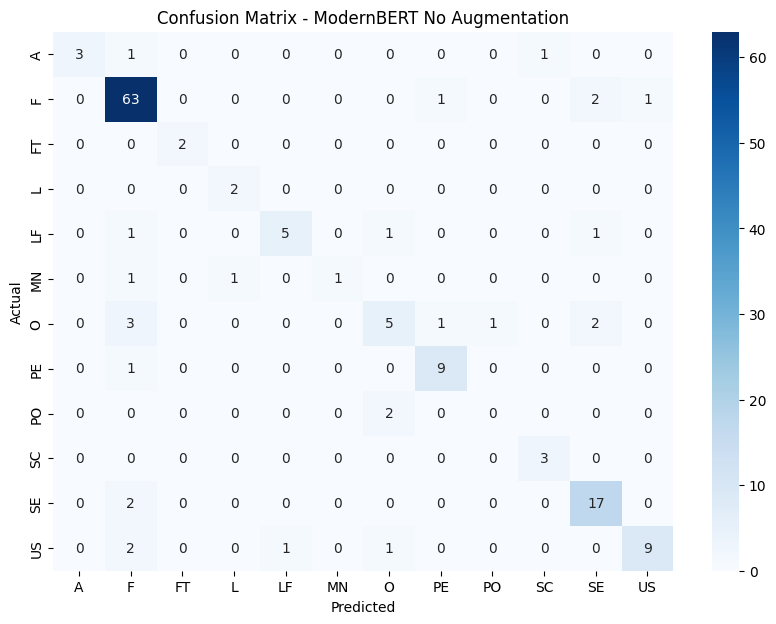

In [6]:
# --- ModernBERT WITHOUT Augmentation ---
train_dataset = make_dataset(train_df)
val_dataset = make_dataset(val_df)
test_dataset = make_dataset(test_df)

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=len(label_encoder.classes_),
)
model = report_trainable_parameters(model)

accuracy_callback = AccuracyPlotCallback()
weight_tensor = compute_class_weights_from_labels(train_df["label"].astype(int).tolist())
trainer = WeightedTrainer(
    model=model,
    args=build_training_args("./results/modernbert_no_augmentation"),
    class_weights=weight_tensor,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    compute_metrics=compute_metrics,
    callbacks=[accuracy_callback],
)

trainer.train()
no_aug_results, no_aug_preds = evaluate_and_plot(trainer, test_dataset, "ModernBERT No Augmentation")


Original train distribution: {'F': np.int64(311), 'SE': np.int64(87), 'US': np.int64(59), 'O': np.int64(54), 'PE': np.int64(47), 'LF': np.int64(34), 'A': np.int64(22), 'MN': np.int64(17), 'SC': np.int64(15), 'FT': np.int64(13), 'L': np.int64(11), 'PO': np.int64(8)}
Augmented train distribution: {'F': np.int64(311), 'PE': np.int64(200), 'FT': np.int64(200), 'US': np.int64(200), 'A': np.int64(200), 'O': np.int64(200), 'LF': np.int64(200), 'SC': np.int64(200), 'MN': np.int64(200), 'PO': np.int64(200), 'L': np.int64(200), 'SE': np.int64(100)}


Loading weights:   0%|          | 0/136 [00:00<?, ?it/s]

[transformers] ModernBertForSequenceClassification LOAD REPORT from: answerdotai/ModernBERT-base
Key               | Status     | 
------------------+------------+-
decoder.bias      | UNEXPECTED | 
classifier.bias   | MISSING    | 
classifier.weight | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
[transformers] warmup_ratio is deprecated and will be removed in v5.2. Use `warmup_steps` instead.


Trainable parameters: 149,614,092 / 149,614,092


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1,Precision Macro,Recall Macro,Macro F1
1,5.042162,2.074003,0.358621,0.461113,0.358621,0.354563,0.252440,0.290136,0.198777
2,2.098637,1.057236,0.648276,0.658989,0.648276,0.640397,0.517279,0.537806,0.509513
3,0.670765,0.916699,0.786207,0.757467,0.786207,0.762512,0.600931,0.619390,0.597834
4,0.102955,0.814840,0.800000,0.797072,0.800000,0.794106,0.666061,0.670370,0.659859
5,0.025145,0.976301,0.793103,0.785473,0.793103,0.786534,0.629444,0.633437,0.623891
6,0.002681,1.007963,0.800000,0.794615,0.800000,0.789756,0.657543,0.648023,0.640419
7,0.000533,1.009497,0.806897,0.796065,0.806897,0.795928,0.654185,0.657456,0.644730
8,0.000126,1.010876,0.813793,0.807944,0.813793,0.804590,0.662897,0.669361,0.653485
9,0.000105,1.019700,0.813793,0.807944,0.813793,0.804590,0.662897,0.669361,0.653485
10,0.000083,1.023202,0.813793,0.807944,0.813793,0.804590,0.662897,0.669361,0.653485


...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

ModernBERT With Augmentation Test metrics: {'accuracy': 0.815068493150685, 'precision': 0.8262660094851877, 'recall': 0.815068493150685, 'f1': 0.8102754722963738, 'precision_macro': 0.8159144096644098, 'recall_macro': 0.7416865151301523, 'macro_F1': 0.7645881121190005}

Classification Report:
              precision    recall  f1-score   support

           A       1.00      0.60      0.75         5
           F       0.86      0.93      0.89        67
          FT       1.00      1.00      1.00         2
           L       1.00      1.00      1.00         2
          LF       0.62      0.62      0.62         8
          MN       0.67      0.67      0.67         3
           O       0.64      0.58      0.61        12
          PE       0.69      0.90      0.78        10
          PO       0.50      0.50      0.50         2
          SC       1.00      0.67      0.80         3
          SE       0.81      0.89      0.85        19
          US       1.00      0.54      0.70        13

  

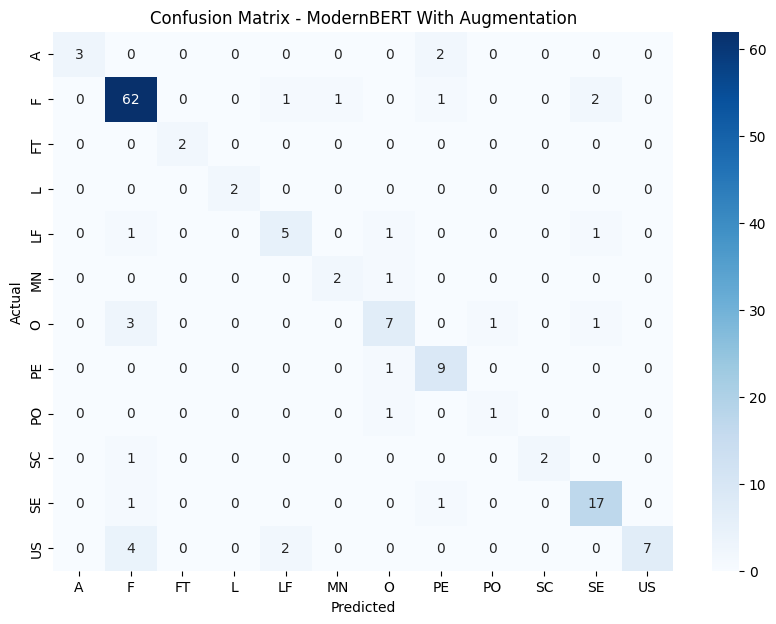

In [7]:
# --- ModernBERT WITH Augmentation ---
augmentation_targets = {
    "FT": 200,
    "L": 200,
    "MN": 200,
    "A": 200,
    "LF": 200,
    "SC": 200,
    "PO": 200,
    "PE": 200,
    "O": 200,
    "US": 200,
    "SE": 100,
}

augmented = []
for cls, min_required in augmentation_targets.items():
    class_df = train_df[train_df["class"] == cls]
    needed = max(0, min_required - len(class_df))
    if len(class_df) == 0 or needed == 0:
        continue
    for _ in range(needed):
        row = class_df.sample(n=1, random_state=random.randint(0, 10**9)).iloc[0]
        aug_text = augment_text(row["RequirementText"])
        augmented.append({
            "RequirementText": aug_text,
            "model_text": aug_text,
            "class": cls,
            "label": row["label"],
        })

df_aug = pd.DataFrame(augmented)
train_aug_df = pd.concat([train_df, df_aug], ignore_index=True) if len(df_aug) > 0 else train_df.copy()
train_aug_df = train_aug_df.sample(frac=1, random_state=RANDOM_STATE).reset_index(drop=True)

print("Original train distribution:", dict(train_df["class"].value_counts()))
print("Augmented train distribution:", dict(train_aug_df["class"].value_counts()))

train_dataset = make_dataset(train_aug_df)
val_dataset = make_dataset(val_df)
test_dataset = make_dataset(test_df)

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=len(label_encoder.classes_),
)
model = report_trainable_parameters(model)

accuracy_callback = AccuracyPlotCallback()
weight_tensor = compute_class_weights_from_labels(train_aug_df["label"].astype(int).tolist())
trainer = WeightedTrainer(
    model=model,
    args=build_training_args("./results/modernbert_with_augmentation"),
    class_weights=weight_tensor,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    compute_metrics=compute_metrics,
    callbacks=[accuracy_callback],
)

trainer.train()
aug_results, aug_preds = evaluate_and_plot(trainer, test_dataset, "ModernBERT With Augmentation")
